<a href="https://colab.research.google.com/github/DiegoMartell/Machine-Learning/blob/main/hands-on/Hands_on_6_kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 6: Clasificación con k-Nearest Neighbors (kNN)
### Implementación paso a paso con Scikit-Learn (Dataset: Breast Cancer)



## 1. Fundamentos Teóricos de la Técnica kNN

El algoritmo **k-Nearest Neighbors (kNN)** es uno de los métodos de aprendizaje supervisado más intuitivos y utilizados tanto para **clasificación** como para **regresión**.

* **¿Cuál es su idea principal?** Se basa en el principio de similitud espacial (*"dime con quién andas y te diré quién eres"*). Para clasificar un nuevo dato desconocido, el algoritmo busca los **$k$ puntos más cercanos** dentro del conjunto de entrenamiento y le asigna la clase que tenga la mayoría entre esos vecinos.
* **Aprendizaje Perezoso (*Lazy Learning*):** A diferencia de otros algoritmos (como la Regresión Logística, SVM o Redes Neuronales), kNN **no construye una ecuación matemática ni ajusta pesos durante el entrenamiento**. Simplemente memoriza los datos de entrenamiento y realiza todos los cálculos de distancia en el momento en que se le pide hacer una predicción.
* **No Paramétrico:** No hace suposiciones sobre la distribución estadística de los datos (no asume que los datos sigan una campana de Gauss ni que sean linealmente separables).
* **El rol crítico del hiperparámetro $k$:**
  * **Valores muy pequeños de $k$ (ej. $k=1$):** El modelo es muy sensible al ruido y a valores atípicos (*Overfitting* o sobreajuste).
  * **Valores muy grandes de $k$:** El modelo suaviza demasiado las fronteras y puede ignorar patrones locales importantes (*Underfitting* o subajuste).
  * **Valores impares de $k$:** En clasificación binaria se recomienda elegir números impares ($k = 3, 5, 7, \dots$) para evitar empates en la votación.
* **Sensibilidad a la escala:** Como kNN mide distancias geométricas entre variables, **es obligatorio escalar los datos**. Si una característica se mide en miles (ej. área del tumor $\approx 1000$) y otra en decimales (ej. suavidad $\approx 0.1$), la variable más grande dominará por completo el cálculo de la distancia.

## 2. Abstracción Matemática

El funcionamiento matemático de kNN se divide en dos operaciones fundamentales: **medir la cercanía** entre muestras y **aplicar la regla de votación**.

### A. Métricas de Distancia
Dados dos vectores de características $\mathbf{p} = (p_1, p_2, \dots, p_n)$ y $\mathbf{q} = (q_1, q_2, \dots, q_n)$ en un espacio de $n$ dimensiones:

1. **Distancia Euclidiana (la más utilizada, distancia en línea recta):**
   $$d_{\text{Euclidiana}}(\mathbf{p}, \mathbf{q}) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

2. **Distancia Manhattan (distancia de cuadrícula o bloque urbano):**
   $$d_{\text{Manhattan}}(\mathbf{p}, \mathbf{q}) = \sum_{i=1}^{n} |p_i - q_i|$$

3. **Distancia de Minkowski (generalización utilizada por defecto en Scikit-Learn):**
   $$d_{\text{Minkowski}}(\mathbf{p}, \mathbf{q}) = \left( \sum_{i=1}^{n} |p_i - q_i|^p \right)^{\frac{1}{p}}$$
   *(Cuando $p = 1$ equivale a la distancia Manhattan; cuando $p = 2$ equivale a la distancia Euclidiana)*.

### B. Regla de Decisión (Votación Mayoritaria)
Para una nueva muestra $\mathbf{x}$, sea $N_k(\mathbf{x})$ el subconjunto formado por los $k$ puntos de entrenamiento con menor distancia a $\mathbf{x}$. La clase predicha $\hat{y}$ corresponde a la moda (clase más frecuente) dentro de ese vecindario:

$$\hat{y} = \arg\max_{c \in \{0, 1\}} \sum_{\mathbf{x}_i \in N_k(\mathbf{x})} \mathbb{I}(y_i = c)$$

*(Donde $\mathbb{I}(y_i = c)$ vale $1$ si el vecino $\mathbf{x}_i$ pertenece a la clase $c$, y $0$ en caso contrario)*.

In [15]:
# Importamos las librerías fundamentales para el manejo de datos y visualización
import numpy as np              # Librería para operaciones numéricas y manejo de arreglos/matrices
import pandas as pd             # Librería para manipulación y análisis de tablas (DataFrames)
import matplotlib.pyplot as plt # Librería base para construir gráficas en Python
import seaborn as sns           # Librería de visualización estadística con estilos mejorados

# Configuramos el estilo visual general de las gráficas
sns.set_theme(style="whitegrid")
print(" Entorno y librerías base cargadas correctamente.")

 Entorno y librerías base cargadas correctamente.


## 3. Pipeline de Machine Learning

### 3.1 Recolección de Datos (Dataset Breast Cancer)
Emplearemos el **Breast Cancer Prediction Dataset** (proveniente de Kaggle: `merishnasuwal/breast-cancer-prediction-dataset`), el cual contiene mediciones extraídas de imágenes digitalizadas de biopsias de masa mamaria.

> 💡 **Nota sobre la carga del archivo:** Para que este notebook funcione de inmediato en Google Colab sin necesidad de configurar credenciales de Kaggle, cargamos el archivo `Breast_cancer_data.csv` desde un espejo público en GitHub. Si descargaste el archivo manualmente desde Kaggle, puedes descomentar la línea local.

In [16]:
# URL con el archivo exacto 'Breast_cancer_data.csv' del dataset de Kaggle
url = "https://raw.githubusercontent.com/Suji04/ML_from_Scratch/master/Breast_cancer_data.csv"

# Leemos el archivo CSV y lo cargamos en un DataFrame de pandas llamado 'df'
df = pd.read_csv(url)


# Mostramos las primeras 5 filas para verificar que los datos se cargaron bien
print("Primeras 5 filas del dataset Breast Cancer:")
display(df.head())

Primeras 5 filas del dataset Breast Cancer:


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0
1,20.57,17.77,132.90,1326.0,0.08474,0
2,19.69,21.25,130.00,1203.0,0.10960,0
3,11.42,20.38,77.58,386.1,0.14250,0
4,20.29,14.34,135.10,1297.0,0.10030,0


### 3.2 Descripción y Análisis Exploratorio del Dataset (EDA)
Antes de entrenar cualquier modelo, inspeccionamos la estructura de nuestros datos:
* **Variables predictoras ($X$):**
  1. `mean_radius`: Radio promedio del núcleo celular.
  2. `mean_texture`: Desviación estándar de los valores en escala de grises (textura).
  3. `mean_perimeter`: Perímetro promedio del tumor.
  4. `mean_area`: Área promedio del tumor.
  5. `mean_smoothness`: Variación local en las longitudes del radio (suavidad).
* **Variable objetivo ($y$):**
  * `diagnosis`: Diagnóstico binario donde **`0` = Maligno** y **`1` = Benigno**.

In [17]:
# Verificamos las dimensiones del dataset (filas, columnas)
print(f"Dimensiones del dataset: {df.shape[0]} muestras y {df.shape[1]} columnas.\n")

# Revisamos los tipos de datos y comprobamos si existen valores nulos (faltantes)
print("--- Valores nulos por columna ---")
print(df.isnull().sum())

# Obtenemos el resumen estadístico (media, desviación estándar, mínimos y máximos)
print("\n--- Resumen Estadístico ---")
display(df.describe())

# Analizamos el balance de clases en la columna objetivo 'diagnosis'
conteo_clases = df['diagnosis'].value_counts()
print("\n--- Distribución del Diagnóstico ---")
print(f"Clase 1 (Benigno): {conteo_clases[1]} muestras")
print(f"Clase 0 (Maligno): {conteo_clases[0]} muestras")

Dimensiones del dataset: 569 muestras y 6 columnas.

--- Valores nulos por columna ---
mean_radius        0
mean_texture       0
mean_perimeter     0
mean_area          0
mean_smoothness    0
diagnosis          0
dtype: int64

--- Resumen Estadístico ---


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,1.000000



--- Distribución del Diagnóstico ---
Clase 1 (Benigno): 357 muestras
Clase 0 (Maligno): 212 muestras


### 3.3 Visualización de Patrones: Scatter Plot
Graficamos un **diagrama de dispersión (*Scatter Plot*)** comparando el **Radio Promedio (`mean_radius`)** contra la **Textura Promedio (`mean_texture`)** para observar cómo se agrupan los tumores benignos y malignos en el plano.

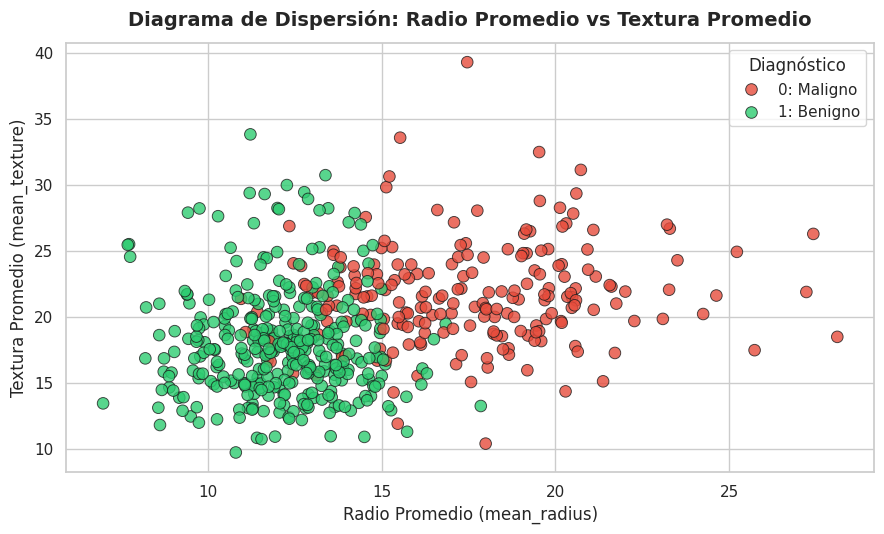

💡 Observa cómo los tumores malignos (rojos) tienden a concentrarse en radios y texturas mayores, formando vecindarios claros que kNN puede aprovechar.


In [18]:
# Creamos una figura de tamaño 9x5.5 pulgadas
plt.figure(figsize=(9, 5.5))

# Dibujamos el Scatter Plot diferenciando cada diagnóstico por color
sns.scatterplot(
    data=df,                          # Fuente de datos
    x='mean_radius',                  # Eje X: Radio promedio
    y='mean_texture',                 # Eje Y: Textura promedio
    hue='diagnosis',                  # Colorear los puntos según la columna 'diagnosis'
    palette={0: '#e74c3c', 1: '#2ecc71'}, # Rojo (0 = Maligno), Verde (1 = Benigno)
    s=70,                             # Tamaño de cada punto
    alpha=0.8,                        # Ligera transparencia para ver puntos superpuestos
    edgecolor='k'                     # Borde negro alrededor de cada punto
)

# Agregamos título y etiquetas descriptivas a los ejes
plt.title('Diagrama de Dispersión: Radio Promedio vs Textura Promedio', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Radio Promedio (mean_radius)', fontsize=12)
plt.ylabel('Textura Promedio (mean_texture)', fontsize=12)

# Personalizamos la leyenda para que sea fácil de interpretar
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=['0: Maligno', '1: Benigno'], title='Diagnóstico', loc='upper right')

plt.tight_layout()
plt.show()

print("💡 Observa cómo los tumores malignos (rojos) tienden a concentrarse en radios y texturas mayores, formando vecindarios claros que kNN puede aprovechar.")

### 3.4 Preprocesamiento de Datos (Splitting y Scaling)
Esta etapa prepara los datos para que kNN funcione con máxima precisión:
1. **Separación de variables ($X$ e $y$):** Aislamos las 5 características clínicas y la etiqueta `diagnosis`.
2. **Splitting (División Train/Test):** Reservamos el 80% de los pacientes para entrenamiento y el 20% para prueba.
3. **Scaling (Escalado Estándar):** Como vimos en el análisis estadístico, `mean_area` alcanza valores superiores a `2000`, mientras que `mean_smoothness` apenas llega a `0.16`. Aplicamos `StandardScaler` para que todas las variables tengan media $0$ y desviación estándar $1$, evitando que el área opaque a las demás variables al calcular distancias.

In [19]:
# Importamos las herramientas de preprocesamiento de Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Definimos la matriz de características X (todas las columnas excepto 'diagnosis')
X = df.drop(columns=['diagnosis']).values

# Definimos el vector objetivo y (columna 'diagnosis')
y = df['diagnosis'].values

# 2. Dividimos en conjunto de entrenamiento (80%) y conjunto de prueba (20%)
# stratify=y mantiene exactamente la misma proporción de tumores benignos y malignos en ambos grupos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Instanciamos el escalador estándar (Z-score)
scaler = StandardScaler()

# Calculamos media y desviación estándar SOLO con X_train y transformamos (evita fuga de datos)
X_train_scaled = scaler.fit_transform(X_train)

# Aplicamos esa misma escala al conjunto de prueba X_test
X_test_scaled = scaler.transform(X_test)

print(f"✅ Preprocesamiento completado:")
print(f"Muestras de entrenamiento: {X_train_scaled.shape[0]} | Muestras de prueba: {X_test_scaled.shape[0]}")

✅ Preprocesamiento completado:
Muestras de entrenamiento: 455 | Muestras de prueba: 114


### 3.5 Selección del Modelo, Búsqueda del Mejor $k$ y Entrenamiento
Siguiendo la metodología del tutorial de referencia, en lugar de elegir un número de vecinos $k$ al azar, evaluaremos valores de **$k$ desde 1 hasta 30** para descubrir cuál ofrece la mayor exactitud (*Accuracy*) en nuestros datos de prueba, y posteriormente entrenaremos el modelo definitivo `KNeighborsClassifier`.

🏆 Mejor valor encontrado: k = 17 vecinos (Exactitud = 91.23%)


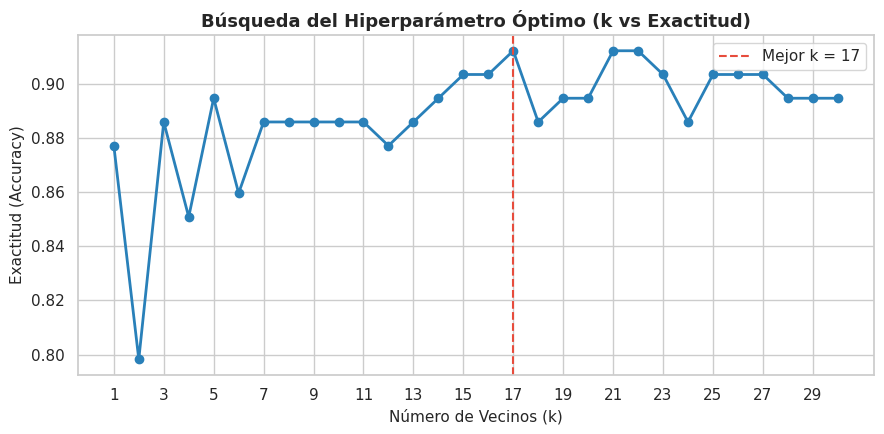

✅ Modelo final KNeighborsClassifier entrenado con k = 17.


In [20]:
# Importamos el clasificador kNN y la métrica de exactitud desde Scikit-Learn
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Creamos una lista para almacenar la exactitud obtenida con cada valor de k
valores_k = range(1, 31)
exactitudes = []

# Iteramos sobre cada posible número de vecinos (de 1 a 30)
for k in valores_k:
    # Instanciamos el modelo kNN con 'k' vecinos y distancia Euclidiana (metric='minkowski', p=2)
    knn_temp = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=2)
    # Entrenamos el modelo con los datos escalados
    knn_temp.fit(X_train_scaled, y_train)
    # Predecimos sobre el conjunto de prueba y guardamos su exactitud
    pred_temp = knn_temp.predict(X_test_scaled)
    exactitudes.append(accuracy_score(y_test, pred_temp))

# Identificamos el valor de k que obtuvo la mayor exactitud
mejor_k = valores_k[np.argmax(exactitudes)]
mejor_acc = max(exactitudes)

print(f"🏆 Mejor valor encontrado: k = {mejor_k} vecinos (Exactitud = {mejor_acc * 100:.2f}%)")

# Graficamos el comportamiento de la exactitud según el número de vecinos k
plt.figure(figsize=(9, 4.5))
plt.plot(valores_k, exactitudes, marker='o', linestyle='-', color='#2980b9', linewidth=2)
plt.axvline(mejor_k, color='#e74c3c', linestyle='--', label=f'Mejor k = {mejor_k}')
plt.title('Búsqueda del Hiperparámetro Óptimo (k vs Exactitud)', fontsize=13, fontweight='bold')
plt.xlabel('Número de Vecinos (k)', fontsize=11)
plt.ylabel('Exactitud (Accuracy)', fontsize=11)
plt.xticks(range(1, 31, 2))
plt.legend()
plt.tight_layout()
plt.show()

# Entrenamos el modelo definitivo utilizando el mejor valor de k encontrado
knn_model = KNeighborsClassifier(n_neighbors=mejor_k, metric='minkowski', p=2)
knn_model.fit(X_train_scaled, y_train)
print(f"✅ Modelo final KNeighborsClassifier entrenado con k = {mejor_k}.")

### 3.6 Evaluación de la Técnica (Métricas, Matriz de Confusión y Frontera de Decisión)
Evaluamos el desempeño clínico del clasificador sobre el conjunto de prueba (`X_test_scaled`) mediante:
1. **Accuracy (Exactitud global):** Porcentaje total de diagnósticos correctos.
2. **Matriz de Confusión:** Desglose de verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos.
3. **Reporte de Clasificación:** Métricas de *Precision*, *Recall* (Sensibilidad) y *F1-Score* para cada diagnóstico.
4. **Frontera de Decisión en 2D y Predicción de un Caso Nuevo:** Visualizamos cómo kNN divide el plano y probamos el modelo con un paciente nuevo.

🎯 Exactitud (Accuracy) Final en Prueba: 91.23%

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

  0: Maligno       0.85      0.93      0.89        42
  1: Benigno       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



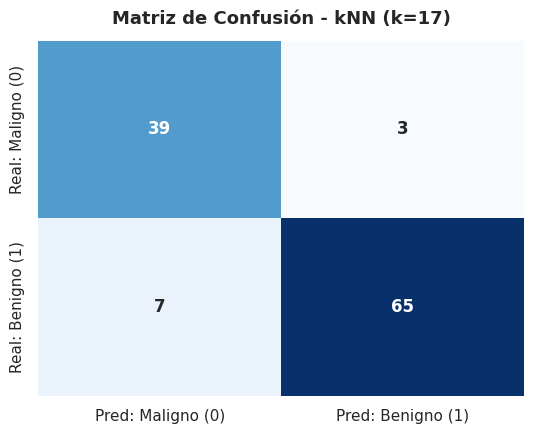

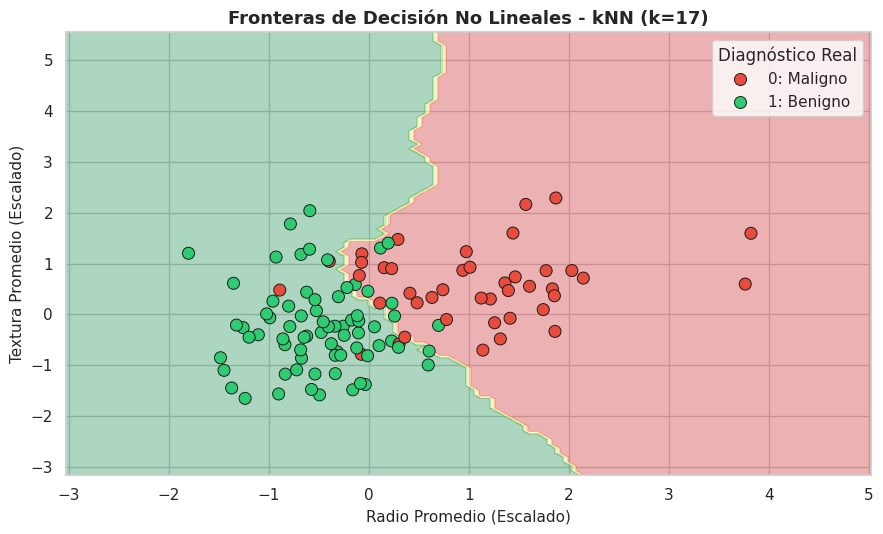

🩺 Diagnóstico predicho para el nuevo paciente: Benigno (1)
   Probabilidad -> Maligno (0): 11.8% | Benigno (1): 88.2%


In [21]:
# Importamos las métricas de evaluación y la herramienta para visualizar fronteras
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.inspection import DecisionBoundaryDisplay

# 1. Realizamos las predicciones sobre los datos de prueba no vistos
y_pred = knn_model.predict(X_test_scaled)

# 2. Calculamos la exactitud final
acc_final = accuracy_score(y_test, y_pred)
print(f"🎯 Exactitud (Accuracy) Final en Prueba: {acc_final * 100:.2f}%\n")

# 3. Mostramos el reporte detallado de clasificación
print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=['0: Maligno', '1: Benigno']))

# 4. Calculamos y graficamos la Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm,
    annot=True,            # Mostrar los números dentro de cada celda
    fmt='d',               # Formato entero
    cmap='Blues',          # Paleta de colores azules
    cbar=False,
    xticklabels=['Pred: Maligno (0)', 'Pred: Benigno (1)'],
    yticklabels=['Real: Maligno (0)', 'Real: Benigno (1)'],
    annot_kws={"size": 12, "weight": "bold"}
)
plt.title(f'Matriz de Confusión - kNN (k={mejor_k})', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# =========================================================
# 5. VISUALIZACIÓN DE FRONTERA DE DECISIÓN EN 2D
# =========================================================
# Entrenamos un modelo auxiliar usando solo las 2 primeras variables (mean_radius y mean_texture)
X_train_2d = X_train_scaled[:, :2]
X_test_2d = X_test_scaled[:, :2]

knn_2d = KNeighborsClassifier(n_neighbors=mejor_k)
knn_2d.fit(X_train_2d, y_train)

plt.figure(figsize=(9, 5.5))
# Dibujamos las regiones de decisión no lineales generadas por los k vecinos
DecisionBoundaryDisplay.from_estimator(
    knn_2d,
    X_train_2d,
    response_method="predict",
    cmap=plt.cm.RdYlGn,
    alpha=0.35,
    ax=plt.gca()
)

# Superponemos los pacientes del conjunto de prueba
sns.scatterplot(
    x=X_test_2d[:, 0],
    y=X_test_2d[:, 1],
    hue=y_test,
    palette={0: '#e74c3c', 1: '#2ecc71'},
    edgecolor='k',
    s=75
)
plt.title(f'Fronteras de Decisión No Lineales - kNN (k={mejor_k})', fontsize=13, fontweight='bold')
plt.xlabel('Radio Promedio (Escalado)', fontsize=11)
plt.ylabel('Textura Promedio (Escalado)', fontsize=11)
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=['0: Maligno', '1: Benigno'], title='Diagnóstico Real')
plt.tight_layout()
plt.show()

# =========================================================
# 6. PREDICCIÓN PARA UN CASO NUEVO (APLICACIÓN PRÁCTICA)
# =========================================================
# Simulamos las mediciones de biopsia de un nuevo paciente: [radius, texture, perimeter, area, smoothness]
nuevo_paciente = np.array([[13.5, 18.2, 87.5, 560.0, 0.095]])

# IMPORTANTE: Escalamos los datos del nuevo paciente con el MISMO scaler del entrenamiento
nuevo_paciente_scaled = scaler.transform(nuevo_paciente)

# Predecimos el diagnóstico y la probabilidad asociada
prediccion_paciente = knn_model.predict(nuevo_paciente_scaled)[0]
probabilidades = knn_model.predict_proba(nuevo_paciente_scaled)[0]
resultado_texto = "Benigno (1)" if prediccion_paciente == 1 else "Maligno (0)"

print(f"🩺 Diagnóstico predicho para el nuevo paciente: {resultado_texto}")
print(f"   Probabilidad -> Maligno (0): {probabilidades[0]*100:.1f}% | Benigno (1): {probabilidades[1]*100:.1f}%")